# WESAD stress detection: S2 deep dive and cohort feature pipeline

**Jillian Melbourne** · HSE.751, Fall 2026

This notebook looks at one participant (S2) in depth, then runs the same feature pipeline on all 15 participants to build the window-level table that the classifier will be trained on.

| # | Section | Scope |
|---|---|---|
| 1 | Dataset selection | — |
| 2 | Dataset overview and project plan | — |
| 3 | Setup and configuration | — |
| 4 | Dataset structure | S2 |
| 5 | Target variable | S2 |
| 6 | Feature pipeline (functions) | — |
| 7 | Data validation and quality flags | S2 |
| 8 | Cohort feature table | all 15 |
| 9 | Descriptive statistics | S2 + cohort |
| 10 | Exploratory visualizations | S2 |
| 11 | Baseline normalization and effect sizes | all 15 |
| 12 | Data quality notes | — |
| 13 | Summary | — |

**Data.** Raw files live in `data/raw/<subject>/<subject>.pkl` (UCI WESAD download). Sections 4–7 and 10 need `S2.pkl`. Sections 8, 9 and 11 use the cached feature table `data/processed/wesad_windows.csv`, so they run without the other 14 pickles; set `REBUILD_FEATURES = True` in section 3 to recompute it from raw data.

## 1. Dataset selection

**Dataset:** WESAD (Wearable Stress and Affect Detection)
**Source:** UC Irvine Machine Learning Repository, https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection

**Why I selected it.** My background is in signal processing for deep brain stimulation and wearables, so WESAD feels like familiar territory with new tools. It contains chest (ECG, EDA, respiration, temperature, EMG, acceleration) and wrist (blood volume pulse, EDA, temperature, acceleration) recordings from 15 participants during a lab stress protocol. Stress is hard to measure beyond self-report yet has major health effects, and wearables offer a promising way to quantify it passively. This project lets me build a complete pipeline from raw signal processing through model evaluation.

| Requirement | Met? | How WESAD meets it |
|---|---|---|
| Binary classification | ✅ | Stress (study label 2) vs. non-stress (baseline + amusement, labels 1 and 3) |
| ≥ 300 observations | ✅ | Each observation is a 60-second window; ~65 per participant × 15 participants ≈ 1,000 |
| ≥ 10 predictors | ✅ | Features engineered per window from both devices (heart rate, HRV, EDA, breathing rate, skin temperature, movement)

## 2. Dataset overview and project plan

S2 is a 27-year-old right-handed man (wrist sensor on the left). His protocol order was baseline → stress → meditation → amusement → meditation.

**Dataset structure.** One pickle holds 10 signal arrays plus a label array, with no missing values. The chest arrays have 4,255,300 rows at 700 Hz. The wrist arrays have between 24,316 rows (EDA and temperature, 4 Hz) and 389,056 rows (BVP, 64 Hz). Every array works out to the same **6,079 s (1 h 41 min 19 s)**, because the authors trimmed both devices to the same synced span. There is no timestamp column; time = row number ÷ sampling rate.

**Target variable.** The `label` array codes the protocol condition at 700 Hz. The binary target is stress (label 2) vs. non-stress (baseline 1 + amusement 3).

**Predictor variables.** There are six chest signals (ECG, EDA, respiration, temperature, EMG, 3-axis acceleration) and four wrist signals (BVP, EDA, temperature, 3-axis acceleration). Each 60-second window is summarized into 15 predictors (section 6):
- heart rate from chest ECG and wrist BVP
- heart rate variability (RMSSD) from chest ECG
- chest and wrist EDA level, chest EDA slope, count of wrist skin conductance responses
- breathing rate and breath-to-breath variability
- chest and wrist temperature, wrist temperature slope
- EMG amplitude (upper trapezius)
- movement variability on each device

Section 11 adds a **baseline-normalized** copy of every predictor (each person's values expressed relative to their own baseline).

### Project plan
- **Proposed prediction problem:** Detect physiological stress from wearable sensor data. Using chest (RespiBAN) and wrist (Empatica E4) recordings from the 15 WESAD participants, predict whether a person was under stress during a given 60-second window, using features engineered from heart rate, HRV, EDA, respiration, skin temperature, muscle activity and movement.
- **Target variable:** Binary stress, where 1 is the Trier Social Stress Test period (WESAD label 2) and 0 is non-stress (baseline and amusement, labels 1 and 3). Transitions, meditation, and "ignore" periods are excluded. Each observation is one 60-second window (30-second step), giving roughly 1,000 windows across all participants.
- **Candidate evaluation metrics:** F1 score on the stress class as the primary metric, with AUROC and balanced accuracy as supporting metrics. Stress is a minority of the usable time, so accuracy would be misleading. Models would be evaluated with leave-one-subject-out cross-validation, because overlapping windows from the same person would otherwise leak between training and test sets and inflate performance.

## 3. Setup and configuration

Every setting the pipeline uses is in the cell below, so a change (window length, filter band, quality threshold) is made in one place. The feature cache records the settings it was built with and is rebuilt automatically if they change.

In [1]:
# ---- Imports ----------------------------------------------------------------
import json
import pickle
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import signal, stats

# ---- Paths ------------------------------------------------------------------
DATA_DIR = Path("data/raw")               # one folder per participant: data/raw/S2/S2.pkl, ...
PROCESSED_DIR = Path("data/processed")    # the window-feature table is cached here
FIG_DIR = Path("figures")                 # every figure is saved here as a PNG
FEATURE_CACHE = PROCESSED_DIR / "wesad_windows.csv"

# ---- Run options ------------------------------------------------------------
SUBJECTS = ["S2", "S3", "S4", "S5", "S6", "S7", "S8", "S9", "S10",
            "S11", "S13", "S14", "S15", "S16", "S17"]   # S1 and S12 were dropped by the authors
EDA_SUBJECT = "S2"          # participant for the single-subject deep dive
REBUILD_FEATURES = False    # True = recompute the feature table from raw data even if the cache is current
SAVE_FIGURES = True

# ---- Windowing --------------------------------------------------------------
WINDOW_S, STEP_S = 60, 30   # 60-s windows, 30-s step (50% overlap)
MIN_LABEL_PURITY = 1.0      # share of a window's samples that must carry one label (1.0 = the whole window)

# ---- Target: WESAD label -> binary stress; every other label is excluded ----
TARGET_MAP = {1: 0, 3: 0, 2: 1}   # baseline -> 0, amusement -> 0, stress -> 1

# ---- Filters (Hz) -----------------------------------------------------------
ECG_BAND = (5, 15)          # QRS energy
BVP_BAND = (0.7, 3.5)       # 42-210 bpm pulse
RESP_BAND = (0.1, 0.7)      # 6-42 breaths/min
EDA_LOWPASS = 1.0
EMG_HIGHPASS = 20           # removes motion and ECG bleed from the trapezius EMG

# ---- Quality thresholds -----------------------------------------------------
HR_RANGE_BPM = (40, 180)    # beat intervals outside this range are rejected
MIN_BEATS = 10              # fewer valid beats in a window -> HR/HRV set to NaN
HR_AGREEMENT_BPM = 10       # chest vs wrist HR gap that flags a likely BVP motion artifact
MAX_IBI_REJECTED = 0.2      # > 20% of chest beat intervals rejected -> ECG artifact flag
TEMP_RANGE_C = (25, 40)     # plausible skin temperature
MIN_WRIST_EDA_US = 0.05     # wrist EDA this close to zero suggests the electrodes lost contact

# ---- Known problems from each participant's readme --------------------------
# Features listed here are set to NaN for that participant.
EXCLUDE_FEATURES = {
    "S2":  ["chest_temp_C"],   # "RespiBAN temperature sensor was not fully attached"
    "S17": ["chest_temp_C"],   # same note
}
# Notes that do not invalidate a signal but matter when reading results.
README_NOTES = {
    "S3":  "Baseline recorded in a sunny workplace (skin temperature).",
    "S5":  "May have fallen asleep during the first meditation (not used here).",
    "S6":  "Reported the TSST interview was not really stressful.",
    "S8":  "Stressful day before the study; felt cold in the stress room (skin temperature).",
    "S9":  "Reported feeling ill on the study day.",
    "S15": "Did not believe the TSST cover story.",
    "S16": "Felt cold in the stress room (skin temperature).",
}

# ---- Sampling rates, units, label names, colours ----------------------------
FS_CHEST = 700                                   # every chest signal AND the label
FS_WRIST = {"ACC": 32, "BVP": 64, "EDA": 4, "TEMP": 4}
CHANNELS = {"chest": ["ACC", "ECG", "EMG", "EDA", "Temp", "Resp"],
            "wrist": ["ACC", "BVP", "EDA", "TEMP"]}
UNITS = {"ACC": "g", "ECG": "mV", "EMG": "mV", "EDA": "µS", "Temp": "°C", "Resp": "%",
         "BVP": "a.u.", "TEMP": "°C"}
LABEL_NAMES = {0: "transient", 1: "baseline", 2: "stress", 3: "amusement", 4: "meditation",
               5: "ignore", 6: "ignore", 7: "ignore"}
COLORS = {1: "#9db4c0", 2: "#e07a5f", 3: "#81b29a", 4: "#c9b6e4"}
CONDITION_ORDER = ["baseline", "amusement", "stress"]

# ---- Display settings -------------------------------------------------------
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
for folder in (PROCESSED_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to FIG_DIR as <name>.png (if SAVE_FIGURES) so the saved copy always matches the notebook."""
    if SAVE_FIGURES:
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | matplotlib {matplotlib.__version__}")

Python 3.10.19 | numpy 2.2.6 | pandas 2.3.3 | scipy 1.15.3 | matplotlib 3.10.8


### 3.1 Loading and validating one participant

`load_subject` reads a participant's pickle and runs `validate_subject` before anything else touches the data. Validation stops with a clear message if a channel is missing, contains NaNs, is flat, has a duration that does not match the label array, or if the label array contains unknown codes. A run therefore fails at the participant that has the problem instead of producing silently wrong features.

If a compact copy `<subject>_compact.npz` (the same arrays as float32) sits next to the pickle, it is read instead because it loads several times faster. It is optional.

In [2]:
def validate_subject(sid, data):
    """Check one participant's raw data. Raises ValueError listing every problem found."""
    problems = []
    for key in ("signal", "label"):
        if key not in data:
            raise ValueError(f"{sid}: file has no '{key}' entry; is this a WESAD pickle?")

    label = np.asarray(data["label"]).ravel()
    duration = len(label) / FS_CHEST
    for device, chans in CHANNELS.items():
        for ch in chans:
            if ch not in data["signal"].get(device, {}):
                problems.append(f"missing {device} {ch}")
                continue
            arr = np.asarray(data["signal"][device][ch])
            fs = FS_CHEST if device == "chest" else FS_WRIST[ch]
            if abs(len(arr) / fs - duration) > 1:          # allow < 1 s rounding at the end
                problems.append(f"{device} {ch} lasts {len(arr) / fs:,.1f} s but the label lasts {duration:,.1f} s")
            n_nan = int(np.isnan(arr).sum())
            if n_nan:
                problems.append(f"{device} {ch} has {n_nan:,} NaN values")
            elif np.std(arr) == 0:
                problems.append(f"{device} {ch} is flat (sensor off?)")

    unknown = set(np.unique(label).astype(int)) - set(LABEL_NAMES)
    if unknown:
        problems.append(f"unknown label codes {sorted(unknown)}")
    if not np.isin(label, list(TARGET_MAP)).any():
        problems.append("no baseline, stress or amusement samples")
    if problems:
        raise ValueError(f"{sid} failed validation:\n  - " + "\n  - ".join(problems))


def load_subject(sid, data_dir=DATA_DIR):
    """Load and validate one participant. Returns dict(subject, chest, wrist, label)."""
    if sid not in SUBJECTS:
        raise ValueError(f"Unknown participant '{sid}'. Valid IDs: {', '.join(SUBJECTS)}")
    folder = Path(data_dir) / sid
    pkl, npz = folder / f"{sid}.pkl", folder / f"{sid}_compact.npz"
    if npz.exists():
        with np.load(npz) as z:
            data = {"label": z["label"],
                    "signal": {dev: {ch: z[f"{dev}_{ch}"] for ch in chans} for dev, chans in CHANNELS.items()}}
    elif pkl.exists():
        with open(pkl, "rb") as f:
            data = pickle.load(f, encoding="latin1")      # saved with Python 2, so latin1 is needed
    else:
        raise FileNotFoundError(f"No data for {sid}: expected {pkl}. Download WESAD from UCI and "
                                f"unzip it so each participant has its own folder in {data_dir}/.")
    validate_subject(sid, data)
    return {"subject": sid, "chest": data["signal"]["chest"], "wrist": data["signal"]["wrist"],
            "label": np.asarray(data["label"]).ravel().astype(int)}


# load the deep-dive participant and pull out the pieces used in sections 4-5
subj = load_subject(EDA_SUBJECT)
chest, wrist, label = subj["chest"], subj["wrist"], subj["label"]
print(f"Loaded {EDA_SUBJECT}: passed validation")

Loaded S2: passed validation


## 4. Dataset structure (S2)

The pickle is a nested dictionary:

```
data
├── "subject"  → "S2"
├── "label"    → one condition code per chest sample (700 Hz)
└── "signal"
    ├── "chest" → ACC, ECG, EMG, EDA, Temp, Resp   (RespiBAN, all 700 Hz)
    └── "wrist" → ACC, BVP, EDA, TEMP              (Empatica E4, 4–64 Hz)
```

There is **no time column**. Time is implicit: `seconds = row number / sampling rate`. The dataset authors trimmed both devices so that row 0 of every array is the same moment. So arrays with very different row counts cover exactly the same span of time.

In [3]:
rows = []
# loop through data types from various sensors and collect metadata for each channel
for device, chans in [("chest", chest), ("wrist", wrist)]:
    for ch, arr in chans.items():
        arr = np.asarray(arr)
        fs = FS_CHEST if device == "chest" else FS_WRIST[ch]
        rows.append({"device": device, "channel": ch, "shape": str(arr.shape), "dtype": str(arr.dtype),
                     "fs_Hz": fs, "duration_s": len(arr) / fs, "duration_min": len(arr) / fs / 60,
                     "units": UNITS[ch], "n_NaN": int(np.isnan(arr).sum())})
rows.append({"device": "label", "channel": "label", "shape": str(label.shape), "dtype": str(label.dtype),
             "fs_Hz": FS_CHEST, "duration_s": len(label) / FS_CHEST,
             "duration_min": len(label) / FS_CHEST / 60, "units": "code", "n_NaN": 0})
structure = pd.DataFrame(rows)
display(structure)

dur = len(label) / FS_CHEST
print(f"Recording length: {len(label):,} rows / {FS_CHEST} Hz = {dur:,.0f} s "
      f"= {int(dur // 3600)} h {int(dur % 3600 // 60)} min {int(dur % 60)} s")
print("Every signal has the same duration:", structure["duration_s"].round(3).nunique() == 1)

,device,channel,shape,dtype,fs_Hz,duration_s,duration_min,units,n_NaN
0,chest,ACC,"(4255300, 3)",float32,700,"6,079.000",101.317,g,0
1,chest,ECG,"(4255300, 1)",float32,700,"6,079.000",101.317,mV,0
2,chest,EMG,"(4255300, 1)",float32,700,"6,079.000",101.317,mV,0
3,chest,EDA,"(4255300, 1)",float32,700,"6,079.000",101.317,µS,0
4,chest,Temp,"(4255300, 1)",float32,700,"6,079.000",101.317,°C,0
5,chest,Resp,"(4255300, 1)",float32,700,"6,079.000",101.317,%,0
6,wrist,ACC,"(194528, 3)",float32,32,"6,079.000",101.317,g,0
7,wrist,BVP,"(389056, 1)",float32,64,"6,079.000",101.317,a.u.,0
8,wrist,EDA,"(24316, 1)",float32,4,"6,079.000",101.317,µS,0
9,wrist,TEMP,"(24316, 1)",float32,4,"6,079.000",101.317,°C,0


Recording length: 4,255,300 rows / 700 Hz = 6,079 s = 1 h 41 min 19 s
Every signal has the same duration: True


Build a time axis for every signal. Rows are **never deleted** from these arrays; selecting by condition is done with a mask (chest) or by mapping each wrist sample's time onto the 700 Hz label (wrist). That way every kept sample still carries its true time.

In [4]:
def time_axis(n, fs):
    """Time in seconds for n samples recorded at fs Hz."""
    return np.arange(n) / fs


def label_at(n, fs, label=label):
    """Condition label for each of n samples recorded at fs Hz (looked up by time on the 700 Hz label)."""
    idx = np.minimum((np.arange(n) * FS_CHEST / fs).astype(int), len(label) - 1)
    return label[idx]


def condition_periods(label):
    """One row per contiguous block of the same condition (used to shade the plots)."""
    change = np.flatnonzero(np.diff(label)) + 1          # sample where the label changes
    starts, ends = np.r_[0, change], np.r_[change, len(label)]
    return pd.DataFrame({"label": label[starts].astype(int),
                         "start_min": starts / FS_CHEST / 60, "end_min": ends / FS_CHEST / 60})


t_chest = time_axis(len(label), FS_CHEST)
periods = condition_periods(label)
wrist_label = {k: label_at(len(v), FS_WRIST[k]) for k, v in wrist.items()}
print("Example: wrist EDA row 1,000 is at", 1000 / 4, "s; chest row", 1000 * 175,
      "is the same moment; label there =", label[1000 * 175], "/", wrist_label["EDA"][1000])

Example: wrist EDA row 1,000 is at 250.0 s; chest row 175000 is the same moment; label there = 0 / 0


## 5. Target variable (S2)

`label` records which part of the study protocol the participant was in. For the project, the binary target is (`TARGET_MAP` in section 3):

| `stress` | WESAD label | Condition |
|---|---|---|
| **1** | 2 | Stress: Trier Social Stress Test (public speech + mental arithmetic) |
| **0** | 1, 3 | Baseline (reading magazines) and amusement (funny videos) |
| excluded | 0, 4, 5–7 | Transitions, meditation, and "ignore" periods |

In [5]:
counts = pd.Series(label).value_counts().sort_index()
target_table = pd.DataFrame({
    "condition": [LABEL_NAMES[int(k)] for k in counts.index],
    "minutes": counts.values / FS_CHEST / 60,
    "% of recording": 100 * counts.values / len(label),
    "binary target": [f"{TARGET_MAP[k]} ({'stress' if TARGET_MAP[k] else 'non-stress'})" if k in TARGET_MAP
                      else "excluded" for k in counts.index]}, index=counts.index.rename("label"))
display(target_table)

usable = np.isin(label, list(TARGET_MAP))
stress_codes = [k for k, v in TARGET_MAP.items() if v == 1]
print(f"Usable for the binary task: {usable.sum() / FS_CHEST / 60:.1f} min "
      f"({usable.mean():.0%} of the recording); "
      f"stress share of usable time = {np.isin(label, stress_codes).sum() / usable.sum():.0%}")

,condition,minutes,% of recording,binary target
label,,,,
0,transient,51.017,50.354,excluded
1,baseline,19.067,18.819,0 (non-stress)
2,stress,10.250,10.117,1 (stress)
3,amusement,6.033,5.955,0 (non-stress)
4,meditation,12.800,12.634,excluded
6,ignore,1.083,1.069,excluded
7,ignore,1.067,1.053,excluded


Usable for the binary task: 35.4 min (35% of the recording); stress share of usable time = 29%


## 6. Feature pipeline

### 6.1 Raw signals

| Device | Signal | Rate | What it measures | Expected stress response |
|---|---|---|---|---|
| Chest | ECG | 700 Hz | Electrical activity of the heart → heart rate and heart rate variability (HRV) | HR ↑, HRV ↓ |
| Chest | EDA | 700 Hz | Skin conductance (sweat gland activity, purely sympathetic) | ↑ level, more responses |
| Chest | Resp | 700 Hz | Chest expansion (piezo belt) → breathing rate and depth | faster, less regular (here also talking) |
| Chest | Temp | 700 Hz | Skin temperature on the chest | small changes; see quality notes |
| Chest | EMG | 700 Hz | Muscle activity (upper trapezius) | ↑ muscle tension |
| Chest | ACC | 700 Hz | 3-axis acceleration (g) → posture and movement | unknown: standing and talking |
| Wrist | BVP | 64 Hz | Blood volume pulse (optical PPG) → pulse rate | HR ↑; motion-sensitive |
| Wrist | EDA | 4 Hz | Skin conductance at the wrist | ↑ |
| Wrist | TEMP | 4 Hz | Skin temperature at the wrist | ↓ (peripheral vasoconstriction) |
| Wrist | ACC | 32 Hz | 3-axis acceleration (1/64 g) → hand/arm movement | unknown |

### 6.2 From raw signals to one row per window

A classifier needs one row per observation. Each row is a **60-second window** (30-second step). The pipeline is three functions so the same code runs on every participant:

1. `preprocess(subj)`: filters each whole recording once (zero-phase Butterworth filters) and downsamples where that loses nothing.
2. `window_features(sig, t0)`: computes the predictors for the window starting at `t0` seconds.
3. `extract_windows(subj)`: slides the window across the recording, keeps windows whose label is in `TARGET_MAP` and at least `MIN_LABEL_PURITY` pure, and adds quality flags (section 7).

| Predictor | Source | Definition |
|---|---|---|
| `chest_hr_bpm`, `chest_rmssd_ms` | ECG | Mean HR and RMSSD from R-peaks (QRS-energy detector) |
| `wrist_hr_bpm` | BVP | Mean HR from pulse peaks |
| `chest_eda_uS`, `chest_eda_slope_uS_per_min` | chest EDA | Mean level and linear trend |
| `wrist_eda_uS`, `wrist_scr_count` | wrist EDA | Mean level and number of skin conductance responses |
| `resp_rate_bpm`, `resp_interval_sd_s` | Resp | Breaths per minute and SD of breath-to-breath intervals (irregularity) |
| `chest_temp_C`, `wrist_temp_C`, `wrist_temp_slope_C_per_min` | Temp | Mean temperatures and wrist trend (vasoconstriction cools the hand) |
| `emg_rms_mV` | EMG | RMS amplitude after a 20 Hz high-pass (muscle tension) |
| `chest_acc_sd_g`, `wrist_acc_sd_g` | ACC | SD of acceleration magnitude (movement) |

In [6]:
def sos(kind, cut, fs, order=4):
    """Second-order sections for a Butterworth filter.
    kind: 'low', 'high' or 'band'; cut: cutoff in Hz, or (low, high) for 'band'."""
    return signal.butter(order, cut, btype=kind, fs=fs, output="sos")


def beats_to_hr(peaks, fs):
    """Heart rate (bpm) and RMSSD (ms) from beat positions, plus the share of beat intervals rejected.
    Intervals outside HR_RANGE_BPM are rejected; with fewer than MIN_BEATS left, HR and RMSSD are NaN."""
    ibi = np.diff(peaks) / fs                                    # gaps between beats in seconds
    ok = (ibi > 60 / HR_RANGE_BPM[1]) & (ibi < 60 / HR_RANGE_BPM[0])
    rejected = 1 - ok.mean() if len(ibi) else 1.0
    ibi = ibi[ok]
    if len(ibi) < MIN_BEATS:
        return np.nan, np.nan, rejected
    return 60 / ibi.mean(), 1000 * np.sqrt(np.mean(np.diff(ibi) ** 2)), rejected


def slope_per_min(x, fs):
    """Linear trend of x in units per minute."""
    return np.polyfit(np.arange(len(x)) / fs / 60, x, 1)[0]


def preprocess(subj):
    """Filter each whole recording once. Returns {name: (signal, sampling rate in Hz)}."""
    chest, wrist = subj["chest"], subj["wrist"]
    ecg = signal.sosfiltfilt(sos("band", ECG_BAND, FS_CHEST), np.ravel(chest["ECG"]))
    # QRS energy: squared derivative smoothed with a 150 ms moving average (105 samples at 700 Hz)
    ecg_energy = np.convolve(np.diff(ecg, prepend=ecg[0]) ** 2, np.ones(105) / 105, mode="same")
    # respiration: low-pass at 5 Hz, downsample 700 -> 10 Hz, then band-pass to breathing frequencies
    resp = signal.sosfiltfilt(sos("low", 5, FS_CHEST), np.ravel(chest["Resp"]))[::70]
    resp = signal.sosfiltfilt(sos("band", RESP_BAND, 10, order=2), resp)
    return {
        "ecg_energy": (ecg_energy, FS_CHEST),
        "bvp":        (signal.sosfiltfilt(sos("band", BVP_BAND, 64, order=2), np.ravel(wrist["BVP"])), 64),
        "resp":       (resp, 10),
        "chest_eda":  (signal.sosfiltfilt(sos("low", EDA_LOWPASS, FS_CHEST), np.ravel(chest["EDA"]))[::175], 4),
        "wrist_eda":  (np.ravel(wrist["EDA"]).astype(float), 4),
        "chest_temp": (np.ravel(chest["Temp"])[::175].astype(float), 4),
        "wrist_temp": (np.ravel(wrist["TEMP"]).astype(float), 4),
        "emg":        (signal.sosfiltfilt(sos("high", EMG_HIGHPASS, FS_CHEST), np.ravel(chest["EMG"])), FS_CHEST),
        "acc_chest":  (np.linalg.norm(np.asarray(chest["ACC"], float), axis=1), FS_CHEST),
        "acc_wrist":  (np.linalg.norm(np.asarray(wrist["ACC"], float) / 64, axis=1), 32),
    }


def cut(sig, name, t0):
    """The WINDOW_S-second slice of signal `name` starting at t0 seconds."""
    x, fs = sig[name]
    return x[int(t0 * fs): int((t0 + WINDOW_S) * fs)]


def window_features(sig, t0):
    """All predictors for the window starting at t0 seconds (plus two beat-rejection rates used for QC)."""
    e = cut(sig, "ecg_energy", t0)
    pk, _ = signal.find_peaks(e, distance=int(60 / HR_RANGE_BPM[1] * FS_CHEST),
                              height=0.3 * np.percentile(e, 99))
    b = cut(sig, "bvp", t0)
    bpk, _ = signal.find_peaks(b, distance=int(60 / HR_RANGE_BPM[1] * 64), prominence=0.3 * b.std())
    r = cut(sig, "resp", t0)
    rpk, _ = signal.find_peaks(r, distance=15, prominence=0.3 * r.std())
    breath_iv = np.diff(rpk) / 10
    we, ce, wt = cut(sig, "wrist_eda", t0), cut(sig, "chest_eda", t0), cut(sig, "wrist_temp", t0)
    scr, _ = signal.find_peaks(we, prominence=0.01, distance=4)
    hr_c, rmssd_c, rej_c = beats_to_hr(pk, FS_CHEST)
    hr_w, _, rej_w = beats_to_hr(bpk, 64)
    return {
        "chest_hr_bpm": hr_c, "chest_rmssd_ms": rmssd_c,
        "wrist_hr_bpm": hr_w,
        "chest_eda_uS": ce.mean(), "chest_eda_slope_uS_per_min": slope_per_min(ce, 4),
        "wrist_eda_uS": we.mean(), "wrist_scr_count": len(scr),
        "resp_rate_bpm": len(rpk) * 60 / WINDOW_S,
        "resp_interval_sd_s": breath_iv.std() if len(breath_iv) >= 3 else np.nan,
        "chest_temp_C": cut(sig, "chest_temp", t0).mean(),
        "wrist_temp_C": wt.mean(), "wrist_temp_slope_C_per_min": slope_per_min(wt, 4),
        "emg_rms_mV": np.sqrt(np.mean(cut(sig, "emg", t0) ** 2)),
        "chest_acc_sd_g": cut(sig, "acc_chest", t0).std(),
        "wrist_acc_sd_g": cut(sig, "acc_wrist", t0).std(),
        "qc_chest_ibi_rejected": rej_c, "qc_wrist_ibi_rejected": rej_w,
    }


def window_label(lab):
    """Most common label in a window and the share of samples that carry it."""
    values, counts = np.unique(lab, return_counts=True)
    i = counts.argmax()
    return int(values[i]), counts[i] / len(lab)


def extract_windows(subj, sig=None):
    """One row per usable window for one participant, with predictors and quality flags."""
    sig = preprocess(subj) if sig is None else sig
    label, sid = subj["label"], subj["subject"]
    rows = []
    for t0 in np.arange(0, len(label) / FS_CHEST - WINDOW_S + 1e-9, STEP_S):
        lab, purity = window_label(label[int(t0 * FS_CHEST): int((t0 + WINDOW_S) * FS_CHEST)])
        if lab not in TARGET_MAP or purity < MIN_LABEL_PURITY:
            continue
        rows.append({"subject": sid, "t_start_min": t0 / 60, "condition": LABEL_NAMES[lab],
                     "stress": TARGET_MAP[lab], "label_purity": purity, **window_features(sig, t0)})
    win = pd.DataFrame(rows)
    for col in EXCLUDE_FEATURES.get(sid, []):          # readme says this channel is unreliable
        win[col] = np.nan
    return add_quality_flags(win)

## 7. Data validation and quality flags

Validation in section 3.1 checks the raw file. The flags below check each **window**. Flagged windows are kept but marked, so a later model can drop them or use them, and the cohort summary in section 8 shows which participants are most affected.

| Flag | Rule | Likely cause |
|---|---|---|
| `flag_hr_missing` | chest or wrist HR is NaN (fewer than `MIN_BEATS` valid beats) | electrode or optical signal lost |
| `flag_hr_disagree` | chest and wrist HR differ by more than `HR_AGREEMENT_BPM` | BVP motion artifact (the two sensors measure the same heart) |
| `flag_ecg_artifact` | more than `MAX_IBI_REJECTED` of chest beat intervals were implausible | noisy ECG, missed or extra R-peaks |
| `flag_temp_range` | wrist or chest temperature outside `TEMP_RANGE_C` | sensor detached |
| `flag_eda_contact` | wrist EDA below `MIN_WRIST_EDA_US` | electrodes not touching the skin |

In [7]:
def add_quality_flags(win):
    """Add one boolean column per quality rule plus flag_any."""
    temp_ok = lambda col: win[col].between(*TEMP_RANGE_C) | win[col].isna()   # NaN = excluded, not flagged
    flags = pd.DataFrame({
        "flag_hr_missing":   win[["chest_hr_bpm", "wrist_hr_bpm"]].isna().any(axis=1),
        "flag_hr_disagree":  (win["chest_hr_bpm"] - win["wrist_hr_bpm"]).abs() > HR_AGREEMENT_BPM,
        "flag_ecg_artifact": win["qc_chest_ibi_rejected"] > MAX_IBI_REJECTED,
        "flag_temp_range":   ~(temp_ok("wrist_temp_C") & temp_ok("chest_temp_C")),
        "flag_eda_contact":  win["wrist_eda_uS"] < MIN_WRIST_EDA_US,
    }, index=win.index)
    flags["flag_any"] = flags.any(axis=1)
    return pd.concat([win, flags], axis=1)


FLAGS = ["flag_hr_missing", "flag_hr_disagree", "flag_ecg_artifact", "flag_temp_range", "flag_eda_contact"]

# run the pipeline on the deep-dive participant
sig = preprocess(subj)
win = extract_windows(subj, sig)
FEATURES = [c for c in win.columns if c not in ("subject", "t_start_min", "condition", "stress", "label_purity")
            and not c.startswith(("qc_", "flag_"))]
print(f"{EDA_SUBJECT}: {len(win)} windows x {len(FEATURES)} predictors")
print(f"Excluded for {EDA_SUBJECT} (readme): {EXCLUDE_FEATURES.get(EDA_SUBJECT, [])}")
display(win[FLAGS + ["flag_any"]].mean().mul(100).rename("% of windows flagged").to_frame())
display(win.head())

S2: 65 windows x 15 predictors
Excluded for S2 (readme): ['chest_temp_C']


,% of windows flagged
flag_hr_missing,0.000
flag_hr_disagree,9.231
flag_ecg_artifact,0.000
flag_temp_range,0.000
flag_eda_contact,0.000
flag_any,9.231


,subject,t_start_min,condition,stress,label_purity,chest_hr_bpm,chest_rmssd_ms,wrist_hr_bpm,chest_eda_uS,chest_eda_slope_uS_per_min,...,chest_acc_sd_g,wrist_acc_sd_g,qc_chest_ibi_rejected,qc_wrist_ibi_rejected,flag_hr_missing,flag_hr_disagree,flag_ecg_artifact,flag_temp_range,flag_eda_contact,flag_any
0,S2,5.500,baseline,0,1.000,74.963,72.034,77.928,4.589,-0.789,...,0.023,0.085,0.014,0.038,False,False,False,False,False,False
1,S2,6.000,baseline,0,1.000,70.963,55.659,77.064,4.189,-0.797,...,0.005,0.035,0.000,0.000,False,False,False,False,False,False
2,S2,6.500,baseline,0,1.000,70.379,57.632,75.650,3.838,-0.606,...,0.004,0.022,0.000,0.000,False,False,False,False,False,False
3,S2,7.000,baseline,0,1.000,73.937,68.696,77.995,3.548,-0.540,...,0.008,0.063,0.000,0.000,False,False,False,False,False,False
4,S2,7.500,baseline,0,1.000,75.140,68.313,79.261,3.315,-0.399,...,0.009,0.081,0.000,0.013,False,False,False,False,False,False


## 8. Cohort feature table (all 15 participants)

`build_feature_table` runs `load_subject → preprocess → extract_windows` for every participant, one at a time (each raw file is about 1 GB, so only one is held in memory). The result is saved to `data/processed/wesad_windows.csv`, together with the settings it was built with (`wesad_windows.json`). Later runs read the CSV in a second; the table is rebuilt only when `REBUILD_FEATURES = True` or when a setting in section 3 has changed. A participant whose file is missing or fails validation is skipped with a message rather than stopping the run.

In [8]:
def pipeline_settings():
    """Settings that change the feature table; stored next to the cache to detect stale results."""
    return {"subjects": SUBJECTS, "features": FEATURES, "window_s": WINDOW_S, "step_s": STEP_S, "min_label_purity": MIN_LABEL_PURITY,
            "target_map": {str(k): v for k, v in TARGET_MAP.items()},
            "filters": {"ecg": ECG_BAND, "bvp": BVP_BAND, "resp": RESP_BAND, "eda_low": EDA_LOWPASS,
                        "emg_high": EMG_HIGHPASS},
            "quality": {"hr_range": HR_RANGE_BPM, "min_beats": MIN_BEATS, "hr_agreement": HR_AGREEMENT_BPM,
                        "max_ibi_rejected": MAX_IBI_REJECTED, "temp_range": TEMP_RANGE_C,
                        "min_wrist_eda": MIN_WRIST_EDA_US},
            "exclude_features": EXCLUDE_FEATURES}


def build_feature_table(subjects=SUBJECTS, rebuild=REBUILD_FEATURES):
    """Window-feature table for all participants: read from cache when current, otherwise rebuilt from raw data."""
    meta_path = FEATURE_CACHE.with_suffix(".json")
    settings = json.loads(json.dumps(pipeline_settings()))          # tuples -> lists, for comparison
    if FEATURE_CACHE.exists() and meta_path.exists() and not rebuild:
        if json.loads(meta_path.read_text()) == settings:
            feats = pd.read_csv(FEATURE_CACHE)
            print(f"Loaded cached feature table {FEATURE_CACHE} ({len(feats):,} windows)")
            return feats
        print("Settings changed since the cache was built -> rebuilding")

    tables, skipped = [], {}
    for sid in subjects:
        try:
            s = load_subject(sid)
            tables.append(extract_windows(s))
            print(f"{sid}: {len(tables[-1])} windows")
        except (FileNotFoundError, ValueError) as err:
            skipped[sid] = str(err)
            print(f"{sid}: SKIPPED - {err}")
        finally:
            s = None                                                 # free ~1 GB before the next participant
    if not tables:
        raise RuntimeError(f"No participant could be processed. Check DATA_DIR ({DATA_DIR.resolve()}).")
    feats = pd.concat(tables, ignore_index=True)
    feats.to_csv(FEATURE_CACHE, index=False)
    meta_path.write_text(json.dumps(settings, indent=2))
    print(f"Saved {len(feats):,} windows from {len(tables)} participants to {FEATURE_CACHE}"
          + (f"; skipped {list(skipped)}" if skipped else ""))
    return feats


feats = build_feature_table()

Loaded cached feature table data/processed/wesad_windows.csv (1,015 windows)


In [9]:
# Per-participant overview: windows per condition, stress share, and quality flags
cohort = (feats.groupby("subject")["condition"].value_counts().unstack(fill_value=0)
               .reindex(columns=CONDITION_ORDER).reindex(SUBJECTS).dropna(how="all"))
cohort["total"] = cohort.sum(axis=1)
cohort["% stress"] = 100 * cohort["stress"] / cohort["total"]
flag_pct = feats.groupby("subject")[FLAGS + ["flag_any"]].mean().mul(100).reindex(cohort.index)
cohort = cohort.join(flag_pct.add_prefix("% ").rename(columns=lambda c: c.replace("flag_", "")))
cohort["readme note"] = [README_NOTES.get(s, "") + (" Chest temp excluded." if s in EXCLUDE_FEATURES else "")
                         for s in cohort.index]
display(cohort)
print(f"Cohort: {len(feats):,} windows from {feats['subject'].nunique()} participants; "
      f"{feats['stress'].mean():.0%} stress; {feats['flag_any'].mean():.0%} carry at least one quality flag")

,baseline,amusement,stress,total,% stress,% hr_missing,% hr_disagree,% ecg_artifact,% temp_range,% eda_contact,% any,readme note
subject,,,,,,,,,,,,
S2,36,10,19,65,29.231,0.000,9.231,0.000,0.000,0.000,9.231,Chest temp excluded.
S3,36,11,20,67,29.851,0.000,43.284,0.000,0.000,0.000,43.284,Baseline recorded in a sunny workplace (skin t...
S4,37,10,19,66,28.788,0.000,4.545,0.000,0.000,0.000,4.545,
S5,38,10,19,67,28.358,0.000,19.403,0.000,0.000,0.000,19.403,May have fallen asleep during the first medita...
S6,37,10,20,67,29.851,0.000,2.985,0.000,0.000,0.000,2.985,Reported the TSST interview was not really str...
S7,37,11,19,67,28.358,0.000,14.925,0.000,0.000,0.000,14.925,
S8,37,10,21,68,30.882,0.000,14.706,0.000,0.000,0.000,14.706,Stressful day before the study; felt cold in t...
S9,37,10,19,66,28.788,0.000,1.515,0.000,0.000,0.000,1.515,Reported feeling ill on the study day.
S10,37,10,22,69,31.884,0.000,17.391,0.000,0.000,0.000,17.391,


Cohort: 1,015 windows from 15 participants; 30% stress; 17% carry at least one quality flag


## 9. Descriptive statistics

### 9.1 S2 window features by condition
Mean and SD of each 60-second window feature for S2, by condition (NaNs are skipped).

In [10]:
summary = (win.groupby("condition")[FEATURES]
              .agg(["mean", "std"])
              .loc[CONDITION_ORDER]      # fix the column order
              .T)                        # one row per feature/statistic
display(summary)
print("Windows per condition:")
display(win["condition"].value_counts().reindex(CONDITION_ORDER).to_frame("n_windows"))

condition                        baseline  amusement  stress
chest_hr_bpm               mean    72.054     66.327  76.017
                           std      1.918      1.499   2.644
chest_rmssd_ms             mean    65.568    107.531  80.374
                           std      8.550     39.706  53.769
wrist_hr_bpm               mean    76.033     75.517  81.612
                           std      3.622      4.285   4.593
chest_eda_uS               mean     1.973      0.757   1.767
                           std      0.945      0.069   0.582
chest_eda_slope_uS_per_min mean    -0.204     -0.032   0.182
                           std      0.219      0.090   0.202
wrist_eda_uS               mean     0.265      0.202   0.862
                           std      0.245      0.024   0.202
wrist_scr_count            mean     3.167      3.200   8.789
                           std      3.621      1.814   3.293
resp_rate_bpm              mean    21.222     20.700  18.000
                           std      1.416      1.337   3.127
resp_interval_sd_s         mean     0.324      0.396   1.264
                           std      0.211      0.166   0.419
chest_temp_C               mean       NaN        NaN     NaN
                           std        NaN        NaN     NaN
wrist_temp_C               mean    35.791     34.190  33.453
                           std      0.101      0.115   0.441
wrist_temp_slope_C_per_min mean    -0.016     -0.060  -0.153
                           std      0.091      0.064   0.052
emg_rms_mV                 mean     0.009      0.009   0.009
                           std      0.001      0.001   0.001
chest_acc_sd_g             mean     0.006      0.004   0.011
                           std      0.003      0.002   0.003
wrist_acc_sd_g             mean     0.036      0.023   0.034
                           std      0.022      0.011   0.026

Windows per condition:


,n_windows
condition,
baseline,36
amusement,10
stress,19


### 9.2 Cohort window features by condition
The same summary for all participants pooled, plus the share of windows where each feature is missing.

In [11]:
cohort_summary = feats.groupby("condition")[FEATURES].mean().loc[CONDITION_ORDER].T
cohort_summary["% missing"] = 100 * feats[FEATURES].isna().mean()
display(cohort_summary)

condition,baseline,amusement,stress,% missing
chest_hr_bpm,72.357,72.539,97.402,0.000
chest_rmssd_ms,52.734,56.229,46.518,0.000
wrist_hr_bpm,74.795,74.892,89.955,0.000
chest_eda_uS,3.885,4.477,5.926,0.000
chest_eda_slope_uS_per_min,-0.043,-0.011,0.103,0.000
wrist_eda_uS,1.320,1.410,3.442,0.000
wrist_scr_count,6.359,5.346,15.142,0.000
resp_rate_bpm,16.136,17.154,15.712,0.000
resp_interval_sd_s,0.637,0.808,1.337,0.000
chest_temp_C,33.797,34.274,34.365,13.202


## 10. Exploratory visualizations (S2)

### Figure 1: Aligned session across multiple sensor modalities
Shaded bands are the labeled conditions; white gaps are transitions (label 0) or "ignore" periods.

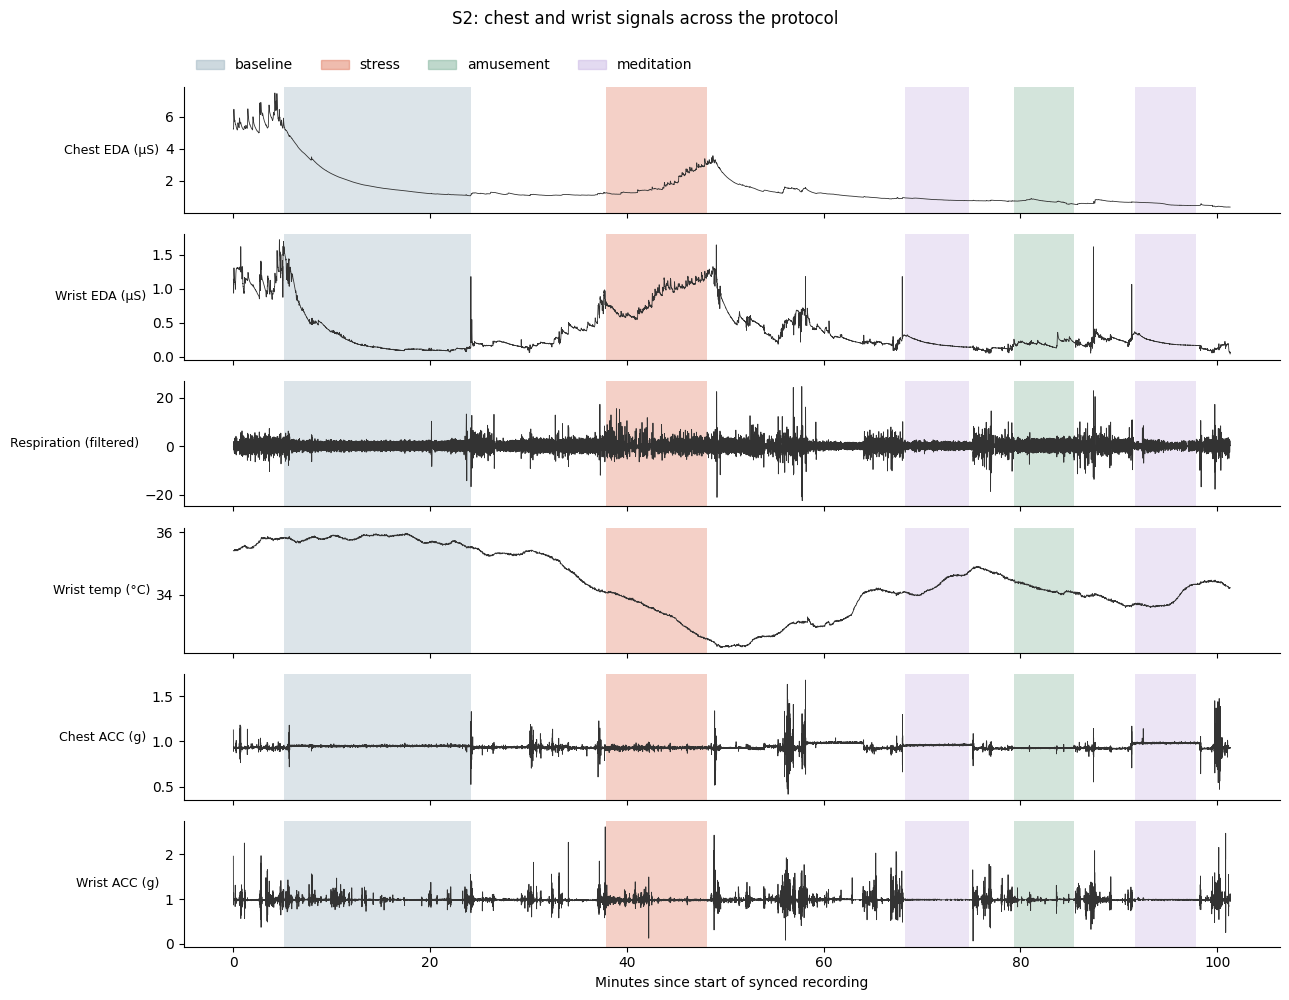

In [12]:
def shade(ax, periods=periods, scale=60):
    """Shade the background of a plot by condition. scale = seconds per x-axis unit (60 = minutes)."""
    for _, period in periods[periods["label"].isin(COLORS)].iterrows():
        ax.axvspan(period.start_min * 60 / scale, period.end_min * 60 / scale,
                   color=COLORS[period.label], alpha=0.35, lw=0)


def condition_legend(ax, labels=COLORS, **kw):
    """Legend of condition colours placed just above an axis."""
    handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[k], alpha=0.5) for k in labels]
    ax.legend(handles, [LABEL_NAMES[k] for k in labels], ncol=len(handles), frameon=False,
              loc="lower left", bbox_to_anchor=(0, 1.02), **kw)


# Each panel is (y-axis label, signal name in `sig`, or a raw array with its sampling rate)
panels = [
    ("Chest EDA (µS)",         *sig["chest_eda"]),
    ("Wrist EDA (µS)",         *sig["wrist_eda"]),
    ("Respiration (filtered)", *sig["resp"]),
    ("Wrist temp (°C)",        *sig["wrist_temp"]),
    ("Chest ACC (g)",          sig["acc_chest"][0][::175], 4),   # 700 Hz -> 4 Hz for plotting
    ("Wrist ACC (g)",          sig["acc_wrist"][0][::8], 4),     # 32 Hz -> 4 Hz
]

fig, axes = plt.subplots(len(panels), 1, figsize=(13, 10), sharex=True)
for ax, (name, y, fs) in zip(axes, panels):
    ax.plot(time_axis(len(y), fs) / 60, y, lw=0.6, color="#333")
    shade(ax)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
condition_legend(axes[0])
axes[-1].set_xlabel("Minutes since start of synced recording")
fig.suptitle(f"{EDA_SUBJECT}: chest and wrist signals across the protocol", y=0.995)
fig.tight_layout()
save_fig(fig, f"fig1_{EDA_SUBJECT}_aligned_session")
plt.show()

### Figure 2: the same 10 seconds on both devices
One minute into baseline and one minute into stress. Each chest heartbeat (ECG) should be followed a fraction of a second later by a pulse at the wrist (BVP).

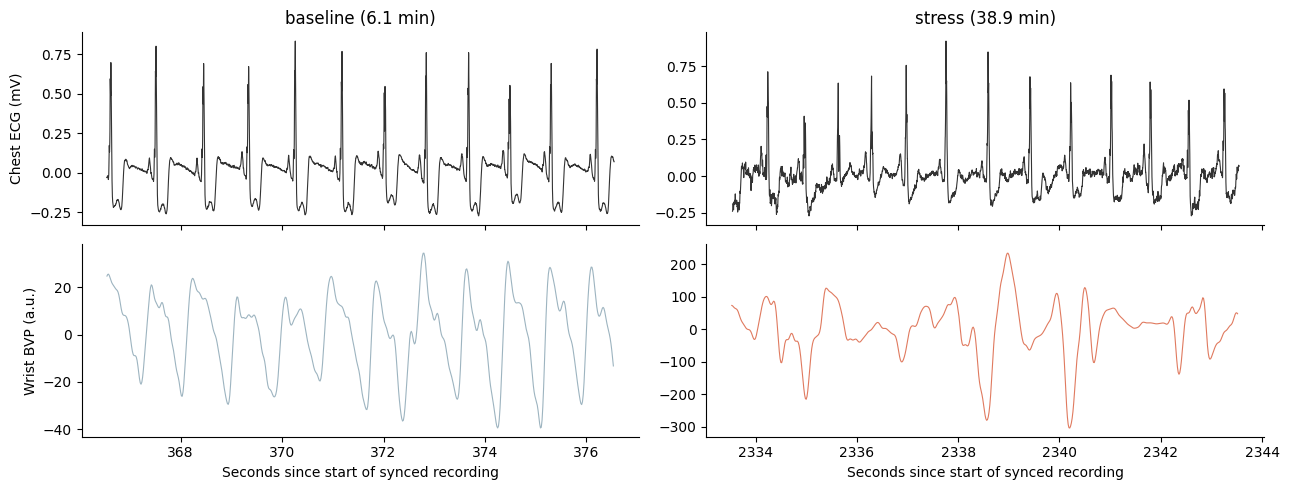

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(13, 5), sharex="col")
signals = [("Chest ECG (mV)",   np.ravel(chest["ECG"]), FS_CHEST),
           ("Wrist BVP (a.u.)", np.ravel(wrist["BVP"]), 64)]

for col, lab in enumerate([1, 2]):                     # 1 = baseline, 2 = stress
    # first sample of this condition (argmax of a boolean = first True), plus 60 s
    t0 = t_chest[np.argmax(label == lab)] + 60
    for row, (name, x, fs) in enumerate(signals):
        start, stop = int(t0 * fs), int((t0 + 10) * fs)
        axes[row, col].plot(time_axis(len(x), fs)[start:stop], x[start:stop],
                            lw=0.8, color=COLORS[lab] if row else "#333")
        axes[row, col].set_ylabel(name if col == 0 else "")
    axes[0, col].set_title(f"{LABEL_NAMES[lab]} ({t0 / 60:.1f} min)")
    axes[1, col].set_xlabel("Seconds since start of synced recording")

fig.tight_layout()
save_fig(fig, f"fig2_{EDA_SUBJECT}_ecg_vs_bvp")
plt.show()

### Figure 3: window features over time
Each dot is one 60-second window, colored by condition. Hollow dots carry at least one quality flag (section 7).

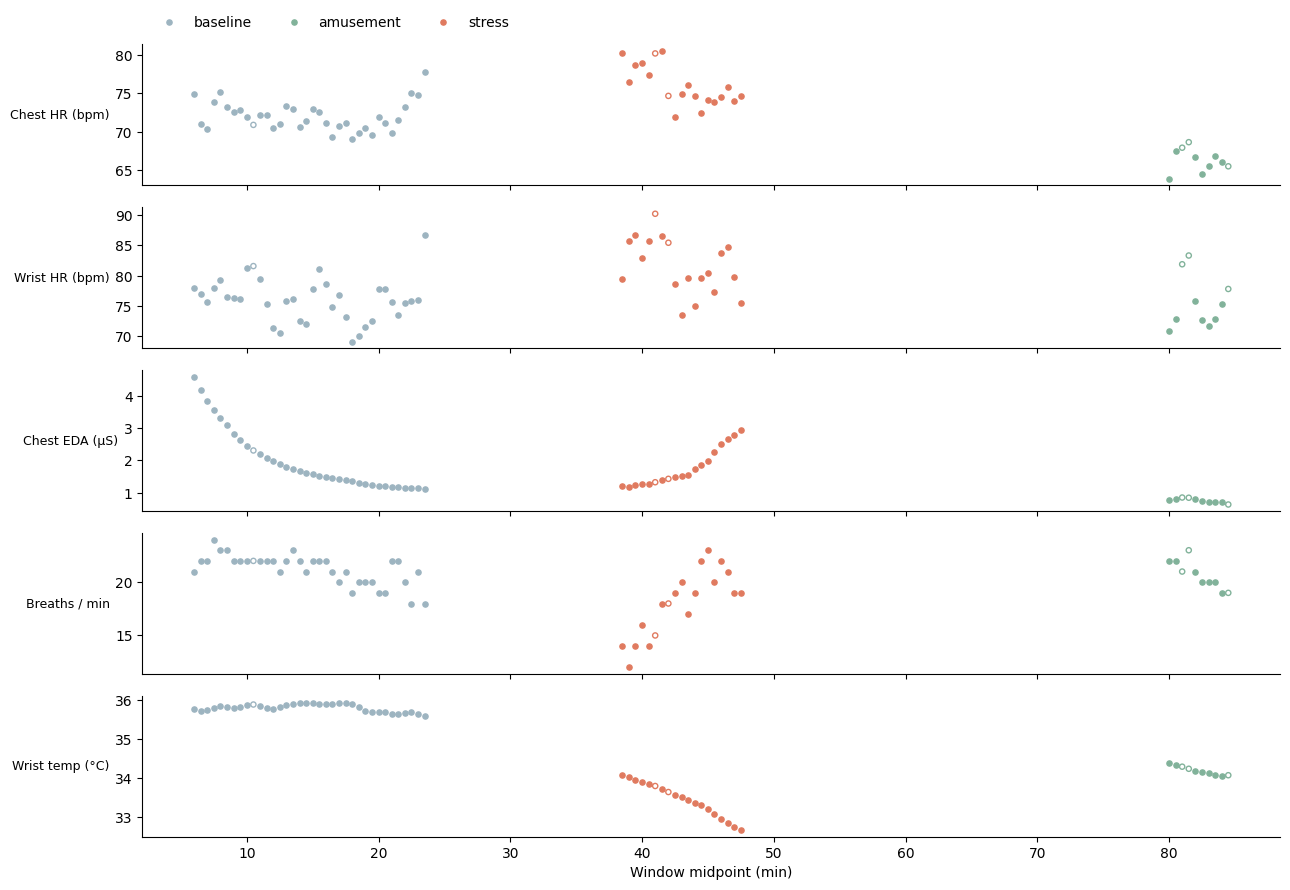

In [14]:
show = [("chest_hr_bpm",  "Chest HR (bpm)"),
        ("wrist_hr_bpm",  "Wrist HR (bpm)"),
        ("chest_eda_uS",  "Chest EDA (µS)"),
        ("resp_rate_bpm", "Breaths / min"),
        ("wrist_temp_C",  "Wrist temp (°C)")]

fig, axes = plt.subplots(len(show), 1, figsize=(13, 9), sharex=True)
for ax, (col, name) in zip(axes, show):
    for lab in (1, 3, 2):                                  # legend order: baseline, amusement, stress
        w = win[win["condition"] == LABEL_NAMES[lab]]
        clean, flagged = w[~w["flag_any"]], w[w["flag_any"]]
        # +0.5 min puts each dot at the window midpoint
        ax.scatter(clean["t_start_min"] + 0.5, clean[col], s=14, color=COLORS[lab], label=LABEL_NAMES[lab])
        ax.scatter(flagged["t_start_min"] + 0.5, flagged[col], s=14, facecolor="none", edgecolor=COLORS[lab])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9)
axes[0].legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02))
axes[-1].set_xlabel("Window midpoint (min)")
fig.tight_layout()
save_fig(fig, f"fig3_{EDA_SUBJECT}_features_over_time")
plt.show()

### Figure 4: feature distributions by condition

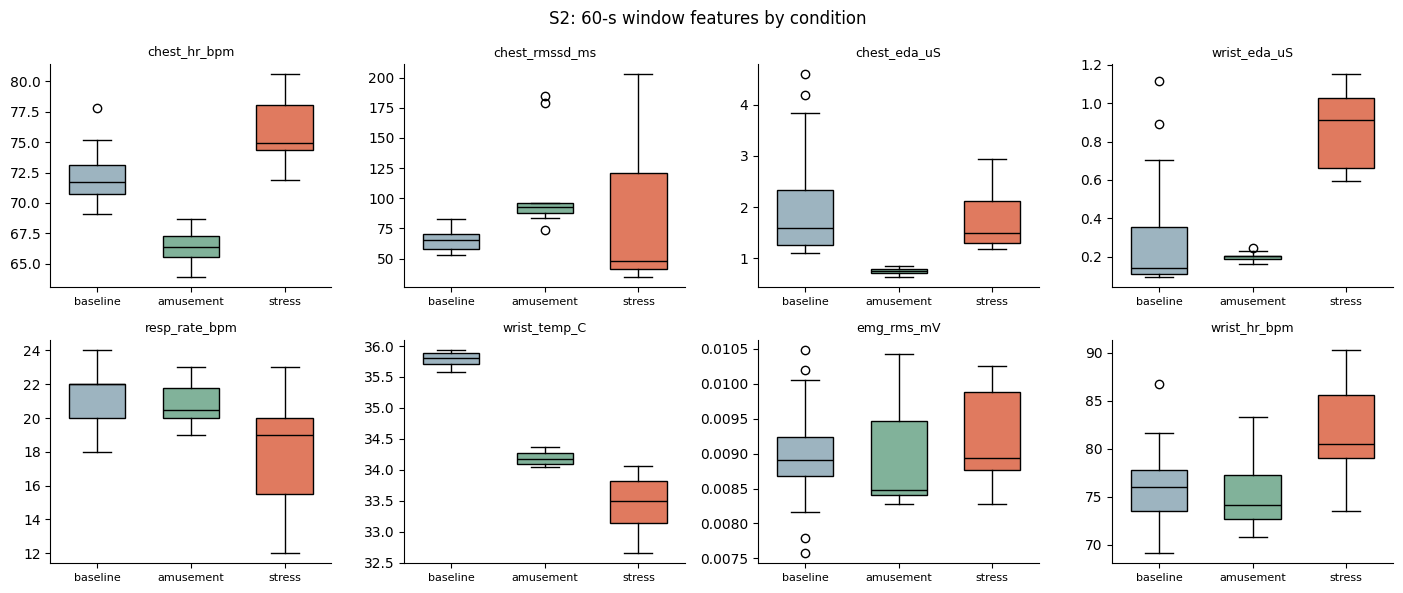

In [15]:
def condition_boxplots(df, feature_list, title, ncols=4):
    """One boxplot panel per feature, boxes ordered baseline / amusement / stress."""
    nrows = int(np.ceil(len(feature_list) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.5 * ncols, 3 * nrows))
    for ax, feat in zip(axes.ravel(), feature_list):
        vals = [df.loc[df["condition"] == c, feat].dropna() for c in CONDITION_ORDER]
        bp = ax.boxplot(vals, patch_artist=True, widths=0.6, medianprops={"color": "black"})
        for patch, lab in zip(bp["boxes"], (1, 3, 2)):
            patch.set_facecolor(COLORS[lab])
        ax.set_xticks([1, 2, 3], CONDITION_ORDER, fontsize=8)
        ax.set_title(feat, fontsize=9)
    for ax in axes.ravel()[len(feature_list):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.tight_layout()
    return fig


box_feats = ["chest_hr_bpm", "chest_rmssd_ms", "chest_eda_uS", "wrist_eda_uS",
             "resp_rate_bpm", "wrist_temp_C", "emg_rms_mV", "wrist_hr_bpm"]
fig = condition_boxplots(win, box_feats, f"{EDA_SUBJECT}: 60-s window features by condition")
save_fig(fig, f"fig4_{EDA_SUBJECT}_feature_distributions")
plt.show()

## 11. Baseline normalization and effect sizes (all participants)

### 11.1 Baseline normalization
People differ a lot in resting heart rate, skin conductance and skin temperature. Pooled across participants, those between-person differences can be larger than the stress effect itself. `baseline_normalize` re-expresses each feature relative to that participant's own resting level:

$$x_{bz} = \frac{x - \text{mean of the participant's baseline windows}}{\text{SD of all the participant's windows}}$$

so 0 means "typical for this person at rest" and the units are comparable across people. The SD is taken over all of the participant's windows, not just baseline, because baseline is very stable for some signals (wrist EDA in particular) and dividing by its tiny SD produced values in the hundreds. No labels are needed for the SD, so this step uses no stress information. This mirrors how a deployed device would calibrate on a short resting recording. One caveat for modelling: in leave-one-subject-out evaluation, the held-out participant's baseline windows are used to normalize their own test windows, which assumes such a calibration recording exists for a new user.

In [16]:
def baseline_normalize(df, features, by="subject", ref="baseline"):
    """Add <feature>_bz columns: (value - participant's baseline mean) / participant's SD over all windows."""
    mu = df[df["condition"] == ref].groupby(by)[features].mean().reindex(df[by]).to_numpy()
    sd = df.groupby(by)[features].std().replace(0, np.nan).reindex(df[by]).to_numpy()  # SD 0 -> NaN, not inf
    z = pd.DataFrame((df[features].to_numpy() - mu) / sd, index=df.index,
                     columns=[f"{f}_bz" for f in features])
    return pd.concat([df.drop(columns=z.columns, errors="ignore"), z], axis=1)


feats = baseline_normalize(feats, FEATURES)
FEATURES_BZ = [f"{f}_bz" for f in FEATURES]
feats.to_csv(PROCESSED_DIR / "wesad_windows_normalized.csv", index=False)
print(f"Added {len(FEATURES_BZ)} baseline-normalized features; saved {PROCESSED_DIR / 'wesad_windows_normalized.csv'}")

Added 15 baseline-normalized features; saved data/processed/wesad_windows_normalized.csv


### Figure 5: what normalization does
Each line is one participant: mean non-stress value (left) to mean stress value (right). Raw values (left panels) sit at very different levels for different people; after normalization (right panels) everyone starts near 0 and the stress shift is easier to see.

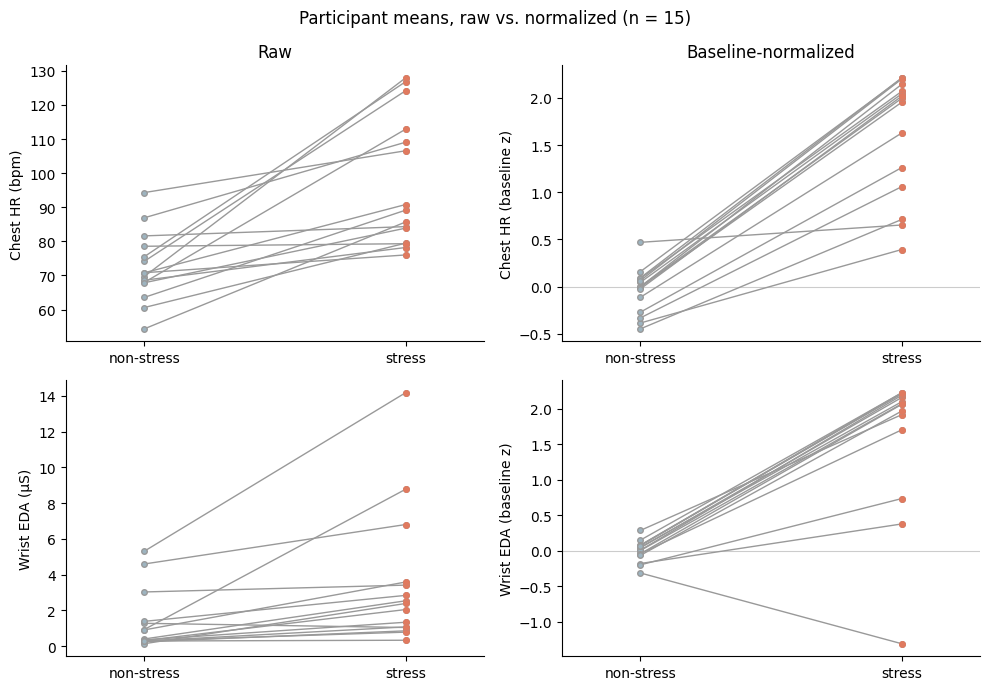

In [17]:
def slope_panel(ax, df, col, ylabel):
    """One line per participant from mean non-stress to mean stress value."""
    means = df.groupby(["subject", "stress"])[col].mean().unstack()
    for _, (non, st) in means[[0, 1]].iterrows():
        ax.plot([0, 1], [non, st], color="#999", lw=1, marker="o", ms=4, mfc=COLORS[1])
        ax.plot([1], [st], marker="o", ms=4, color=COLORS[2])
    ax.set_xticks([0, 1], ["non-stress", "stress"])
    ax.set_xlim(-0.3, 1.3)
    ax.set_ylabel(ylabel)


pairs = [("chest_hr_bpm", "Chest HR (bpm)"), ("wrist_eda_uS", "Wrist EDA (µS)")]
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for row, (col, name) in enumerate(pairs):
    slope_panel(axes[row, 0], feats, col, name)
    slope_panel(axes[row, 1], feats, f"{col}_bz", f"{name.split(' (')[0]} (baseline z)")
    axes[row, 1].axhline(0, color="#ccc", lw=0.8, zorder=0)
axes[0, 0].set_title("Raw")
axes[0, 1].set_title("Baseline-normalized")
fig.suptitle(f"Participant means, raw vs. normalized (n = {feats['subject'].nunique()})")
fig.tight_layout()
save_fig(fig, "fig5_cohort_baseline_normalization")
plt.show()

### 11.2 Effect sizes: which features separate stress from non-stress?
For every feature, **Cohen's d** (stress mean − non-stress mean, in pooled-SD units; |d| ≈ 0.2 small, 0.5 medium, 0.8 large) is computed three ways:

- **within-participant d**, one per participant, summarized by the median and by how many participants show the same direction. This is the most honest view of a feature's signal, and normalization does not change it.
- **pooled raw d**: all windows together, raw values.
- **pooled normalized d**: all windows together, baseline-normalized values. If normalization works, this moves toward the within-participant d.

The Mann–Whitney U p-value (pooled normalized values) is a rough guide only: overlapping windows from the same person are not independent, so p-values are too small.

In [18]:
def cohens_d(x1, x0):
    """Cohen's d for x1 vs x0 (pooled SD); NaN if either group has fewer than 2 values."""
    x1, x0 = pd.Series(x1).dropna(), pd.Series(x0).dropna()
    if len(x1) < 2 or len(x0) < 2:
        return np.nan
    pooled = np.sqrt(((len(x1) - 1) * x1.var() + (len(x0) - 1) * x0.var()) / (len(x1) + len(x0) - 2))
    return (x1.mean() - x0.mean()) / pooled if pooled > 0 else np.nan


def effect_sizes(df, features):
    """Per-participant d (subjects x features) and a summary table ranked by |median within-participant d|."""
    per_subject = pd.DataFrame({f: {s: cohens_d(g.loc[g.stress == 1, f], g.loc[g.stress == 0, f])
                                    for s, g in df.groupby("subject")} for f in features})
    per_subject = per_subject.reindex([s for s in SUBJECTS if s in per_subject.index])
    rows = []
    for f in features:
        d = per_subject[f].dropna()
        st, non = df.loc[df.stress == 1, f"{f}_bz"].dropna(), df.loc[df.stress == 0, f"{f}_bz"].dropna()
        rows.append({"feature": f,
                     "median within-participant d": d.median(),
                     "same direction (n/N)": f"{int((np.sign(d) == np.sign(d.median())).sum())}/{len(d)}",
                     "pooled raw d": cohens_d(df.loc[df.stress == 1, f], df.loc[df.stress == 0, f]),
                     "pooled normalized d": cohens_d(st, non),
                     "Mann-Whitney p (normalized)": stats.mannwhitneyu(st, non).pvalue
                                                    if len(st) and len(non) else np.nan})
    table = pd.DataFrame(rows).set_index("feature")
    order = table["median within-participant d"].abs().sort_values(ascending=False).index
    return per_subject[order], table.loc[order]


d_by_subject, effects = effect_sizes(feats, FEATURES)
display(effects.style.format({"median within-participant d": "{:+.2f}", "pooled raw d": "{:+.2f}",
                              "pooled normalized d": "{:+.2f}", "Mann-Whitney p (normalized)": "{:.1e}"}))

AttributeError: The '.style' accessor requires jinja2

### Figure 6: features ranked by effect size
Grey dots are individual participants; the bar is the median within-participant d; the black diamond is the pooled baseline-normalized d. Bars to the right mean the feature is higher under stress. The x-axis is linear between −1 and 1 and logarithmic beyond, because within-participant d can be very large: each person's windows within one condition vary little, and neighbouring windows overlap. Pooled d is the more realistic guide to how well a feature will separate unseen people.

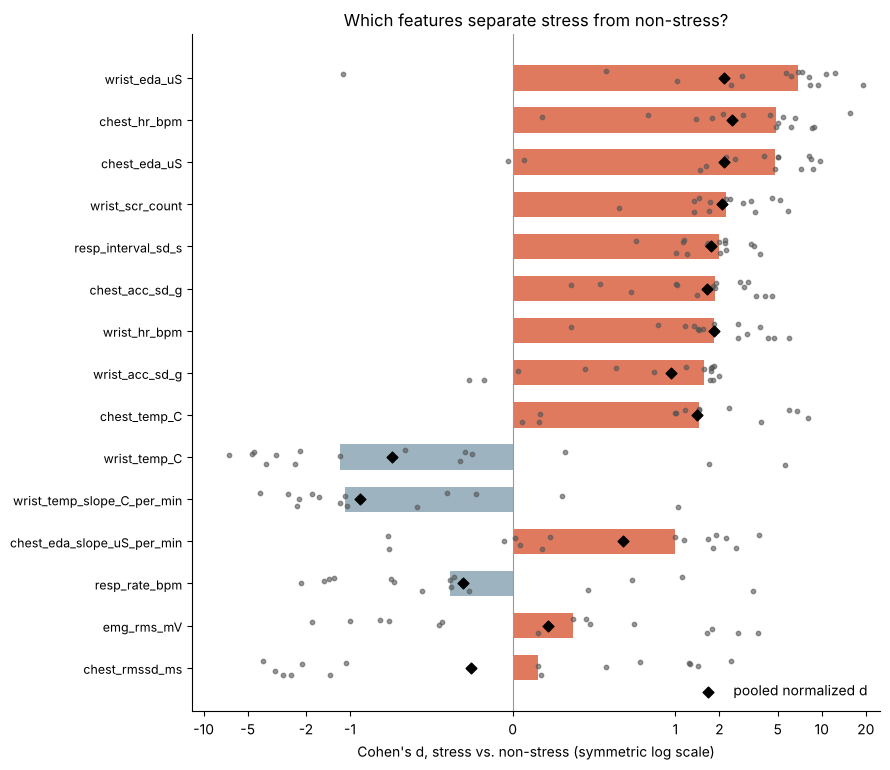

In [ ]:
order = effects.index[::-1]                                   # largest effect at the top
fig, ax = plt.subplots(figsize=(9, 0.42 * len(order) + 1.5))
y = np.arange(len(order))
median_d = effects.loc[order, "median within-participant d"]
ax.barh(y, median_d, color=np.where(median_d > 0, COLORS[2], COLORS[1]), height=0.6)
for i, f in enumerate(order):
    d = d_by_subject[f].dropna()
    ax.scatter(d, np.full(len(d), i) + np.random.default_rng(0).uniform(-0.18, 0.18, len(d)),
               s=10, color="#555", alpha=0.6, zorder=3)
ax.scatter(effects.loc[order, "pooled normalized d"], y, marker="D", s=30, color="black", zorder=4,
           label="pooled normalized d")
ax.axvline(0, color="#999", lw=0.8)
ax.set_yticks(y, order, fontsize=9)
ax.set_xscale("symlog", linthresh=1)                          # linear within ±1, log beyond
ax.set_xticks([-10, -5, -2, -1, 0, 1, 2, 5, 10, 20], ["-10", "-5", "-2", "-1", "0", "1", "2", "5", "10", "20"])
ax.set_xlim(-12, 25)
ax.set_xlabel("Cohen's d, stress vs. non-stress (symmetric log scale)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Which features separate stress from non-stress?")
fig.tight_layout()
save_fig(fig, "fig6_cohort_effect_sizes")
plt.show()

### Figure 7: effect size by participant
Rows are participants, columns are features (same order as Figure 6). Red = higher under stress, blue = lower, grey = not available. A feature whose column is one colour top to bottom works for everyone; a mixed column only works for some people.

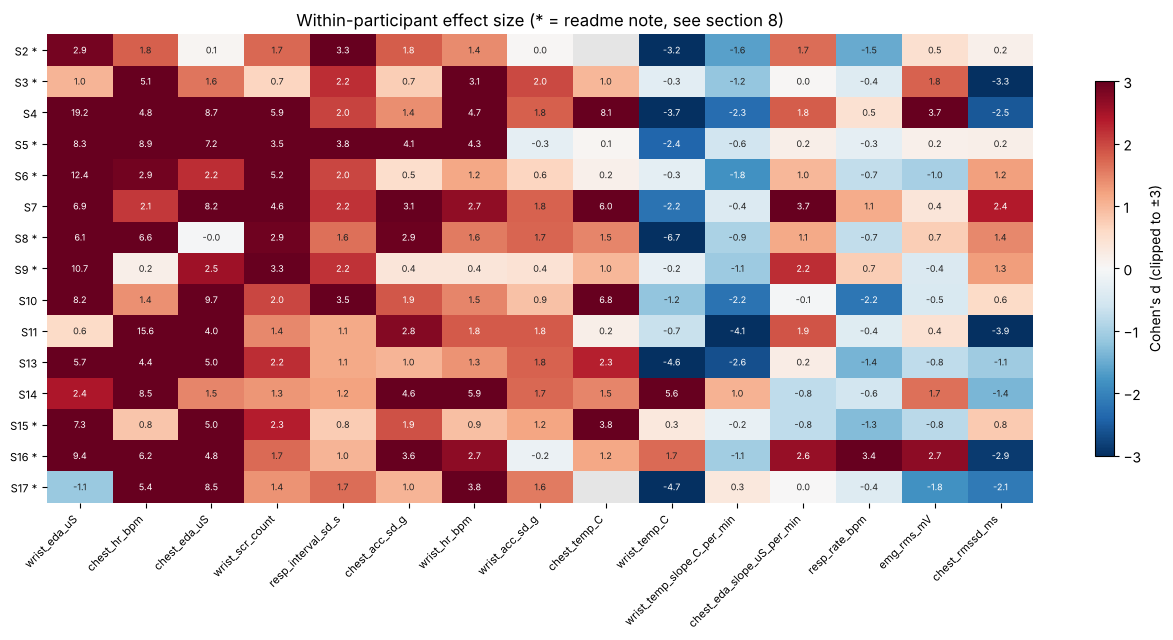

In [ ]:
mat = d_by_subject.clip(-3, 3)
fig, ax = plt.subplots(figsize=(13, 6.5))
cmap = plt.get_cmap("RdBu_r").copy()
cmap.set_bad("#e5e5e5")
im = ax.imshow(np.ma.masked_invalid(mat.to_numpy()), cmap=cmap, vmin=-3, vmax=3, aspect="auto")
for (i, j), v in np.ndenumerate(d_by_subject.to_numpy()):
    if np.isfinite(v):
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(v) > 1.8 else "#222")
ax.set_xticks(range(mat.shape[1]), mat.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(mat.shape[0]),
              [f"{s} *" if s in README_NOTES or s in EXCLUDE_FEATURES else s for s in mat.index], fontsize=8)
for side in ("top", "right", "left", "bottom"):
    ax.spines[side].set_visible(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Cohen's d (clipped to ±3)")
ax.set_title("Within-participant effect size (* = readme note, see section 8)")
fig.tight_layout()
save_fig(fig, "fig7_cohort_effect_heatmap")
plt.show()

## 12. Data quality notes

- **Participant-specific problems.** Each participant's readme lists known issues. Chest temperature is excluded for S2 and S17 (sensor not fully attached). Other notes that may weaken the stress signal are listed in the section 8 table and starred in Figure 7: S6 and S15 reported the TSST was not really stressful or did not believe it, and S8 and S16 felt cold in the stress room, which confounds skin temperature.
- **Signal vs. noise.** Noise is common in wearable data. The chest and wrist devices both measure heart rate, so disagreement between them (`flag_hr_disagree`) is a direct, per-window check on wrist BVP motion artifact, which is most likely during the TSST speech when participants stand and gesture.
- **Class imbalance.** More of the session is spent at baseline and amusement than in the stress condition (about a third of usable windows are stress), so accuracy alone would be misleading.
- **Movement and speech confounds.** The TSST has participants stand and talk, so movement (`chest_acc_sd_g`, `wrist_acc_sd_g`) and breathing irregularity (`resp_interval_sd_s`) rise under stress partly for mechanical reasons. They will help the classifier on WESAD but may not transfer to stress that happens while sitting still.
- **Window dependence.** Windows overlap by 50% and come from only 15 people, so they are not independent. Evaluation must be leave-one-subject-out, and p-values in section 11 are optimistic.
- **No wrist HRV.** RMSSD from wrist BVP was tried and dropped: it came out at 170–350 ms against about 50 ms from the chest ECG, because pulse-peak timing at 64 Hz (16 ms resolution) and occasional spurious peaks dominate beat-to-beat differences. Wrist heart rate (an average over many beats) is still usable.
- **Chest HR can also fail.** In some stress windows the chest HR runs far above wrist HR (for example S11), which suggests the ECG detector is also counting T-waves while the participant talks. `flag_hr_disagree` marks these windows; refining the R-peak detector is a next step.

## 13. Summary

- WESAD gives a clean binary target (TSST stress vs. baseline + amusement) and two time-aligned wearable devices.
- The feature pipeline is now a set of functions (`load_subject`, `preprocess`, `extract_windows`, `build_feature_table`) controlled from one configuration cell, and produces 15 predictors for every 60-second window from all 15 participants, cached in `data/processed/`.
- Each raw file is validated on load, each window carries quality flags, and channels the dataset authors marked as unreliable are excluded.
- Baseline normalization removes most of the between-person offset, and the effect-size summary (Figures 6 and 7) shows which features shift consistently under stress and for how many participants. Those results will guide feature selection for the leave-one-subject-out classifier.